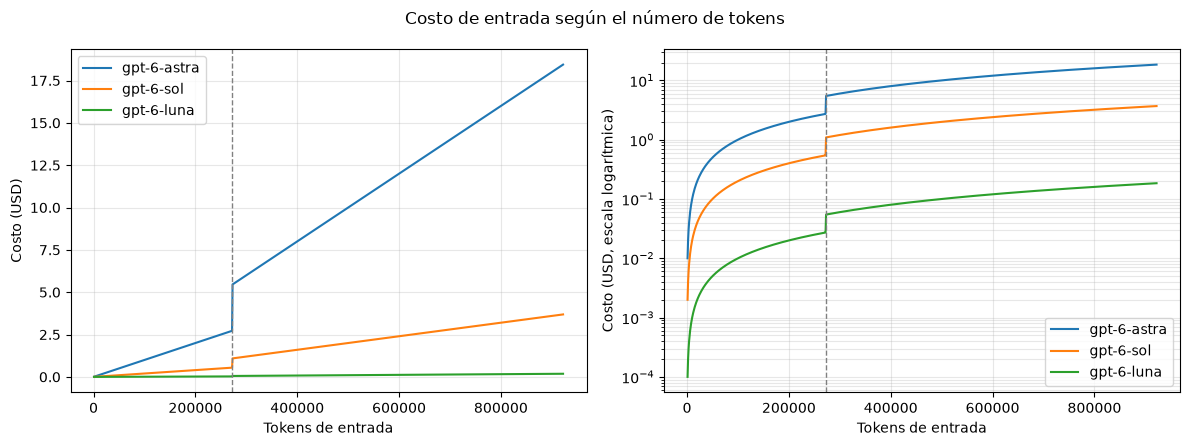

20.0
20.0
20.0
20.0
20.0
20.0


In [10]:
import matplotlib.pyplot as plt

def costo_entrada(modelo, tokens):
    """Costo en USD de una solicitud con `tokens` tokens de entrada al `modelo`."""
    modelos = {
    #modelo [short contex, long context, max token]
    "gpt-6-astra": [10, 20, 1050000],
    "gpt-6-sol": [2, 4, 1050000],
    "gpt-6-luna": [.10, .20, 1050000]

    }

    if modelo not in modelos:
        raise ValueError
    if tokens < 0:
        raise ValueError

    short_context, long_context, max_token = modelos[modelo]

    if tokens >= max_token:
        raise ValueError()

    umbral = 272000

    if tokens > umbral:
        tarifa_por_millon = long_context
    else:
        tarifa_por_millon = short_context


    costo_total = (tokens / 1000000) * tarifa_por_millon
    return costo_total


def graficar_costos(tokens, costos_por_modelo, archivo="costos_api.png"):
    """Dibuja el costo de entrada frente al número de tokens.

    tokens: lista de enteros (eje x).
    costos_por_modelo: diccionario modelo -> lista de costos en USD, uno por valor de tokens.
    """
    fig, (lineal, logaritmica) = plt.subplots(1, 2, figsize=(12, 4.5))
    for modelo, costos in costos_por_modelo.items():
        lineal.plot(tokens, costos, label=modelo)
        logaritmica.plot(tokens, costos, label=modelo)
    for ax in (lineal, logaritmica):
        ax.axvline(272_000, color="gray", linestyle="--", linewidth=1)
        ax.set_xlabel("Tokens de entrada")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend()
    lineal.set_ylabel("Costo (USD)")
    logaritmica.set_ylabel("Costo (USD, escala logarítmica)")
    logaritmica.set_yscale("log")
    fig.suptitle("Costo de entrada según el número de tokens")
    fig.tight_layout()
    fig.savefig(archivo, dpi=150)
    plt.show()


modelos = ["gpt-6-astra", "gpt-6-sol", "gpt-6-luna"]
tokens = list(range(1_000, 922_001, 1_000))
costos = {m: [costo_entrada(m, n) for n in tokens] for m in modelos}
graficar_costos(tokens, costos)

costos = [1000,	5000, 10000, 272000, 300000, 922000]
for costo in costos:
    print(costo_entrada('gpt-6-astra', 1000000))